In [44]:
import numpy as np
import matplotlib.pyplot as plt

# Wczytamy obraz, uśrednimy kanały barwne, zmiejszymy go
image = plt.imread('avo.JPG')
image = np.mean(image, axis=2).astype('uint8')
image = image[::7, ::7]
image.shape

(106, 105)

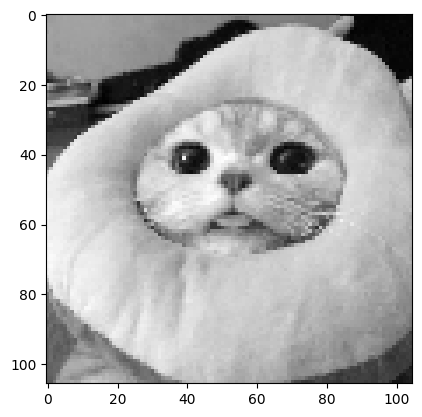

In [45]:
plt.imshow(image, cmap='binary_r')

In [46]:
# Zdefiniujemy prostą funkcję transformacji

T = np.random.choice(np.arange(0,255,50),size=(256))
T = np.sort(T)
T

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,  50,  50,  50,  50,
        50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,
        50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,
        50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,  50,
        50,  50,  50,  50, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100,
       100, 100, 100, 100, 150, 150, 150, 150, 150, 150, 150, 150, 150,
       150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150,
       150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150, 150,
       150, 150, 150, 150, 200, 200, 200, 200, 200, 200, 200, 20

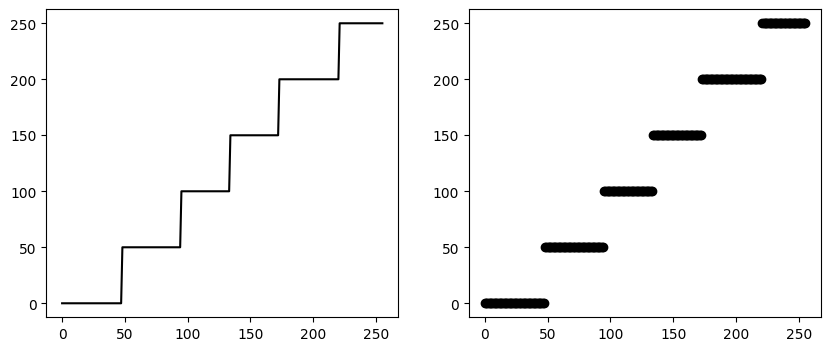

In [47]:
# Zobaczymy jak wygląda
fig, ax = plt.subplots(1,2, figsize=(10,4))

ax[0].plot(np.arange(len(T)), T, c='k')
ax[1].scatter(np.arange(len(T)), T, c='k')

# T to też *Look-up-table*

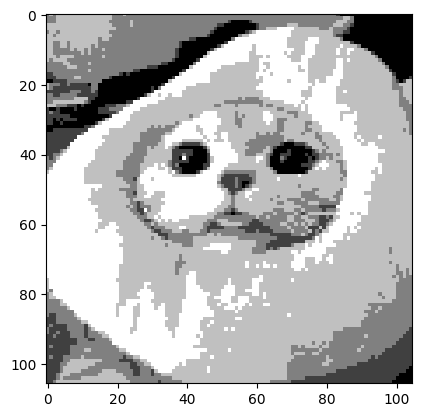

In [48]:
# Przekształcimy obraz zgodnie z funkcją T
image_T = T[image]

plt.imshow(image_T, cmap='binary_r')

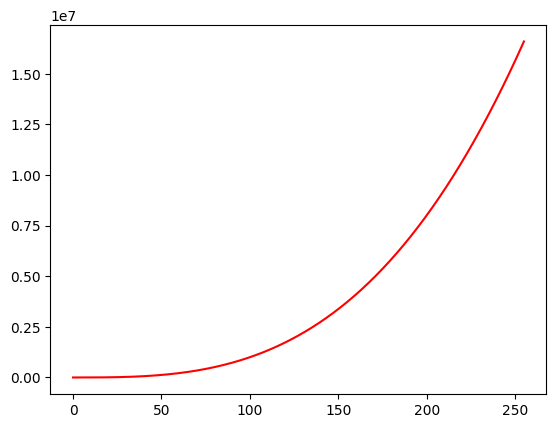

In [49]:
# Przykład trochę bardziej ciągły

T = np.arange(256)
T = T**3

plt.plot(np.arange(len(T)), T, c='red')

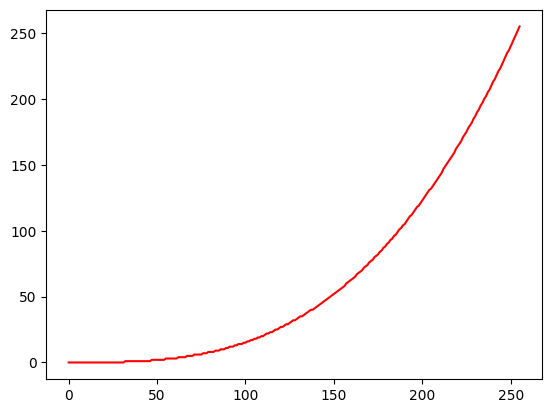

In [50]:
# Naprawmy

T = np.copy(T).astype(float)
T -= np.min(T)
T /= np.max(T)
T = np.rint(T*255).astype(int)

plt.plot(np.arange(len(T)), T, c='red')

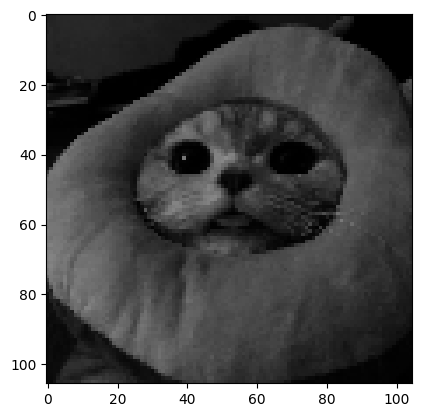

In [51]:
image_T = T[image]

plt.imshow(image_T, cmap='binary_r', vmin=0, vmax=255)

In [52]:
# Pora na histogram

pixel_values = image_T.flatten()
pixel_values[:100]

array([35, 37, 36, 40, 40, 41, 40, 41, 40, 40, 40, 40, 40, 38, 40, 39, 40,
       39, 37, 35, 35, 35, 37, 36, 36, 36, 35, 34, 33, 32, 35, 32, 32, 32,
       29, 29, 29, 28, 28, 27, 27, 26, 28, 27, 27, 27, 25, 25, 25, 25, 23,
       25, 22, 23, 23, 23, 23, 20, 20, 21, 22, 23, 22, 22, 20, 20, 19, 20,
       20, 19, 20, 19, 20, 19, 19, 18, 18, 18, 18, 18, 17, 18, 17, 11,  1,
        1,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0])

In [53]:
u, c = np.unique(pixel_values, return_counts=True)
u, c

(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  60,  61,  62,  63,  64,  65,
         67,  68,  69,  70,  72,  73,  74,  76,  77,  78,  80,  81,  82,
         84,  85,  87,  88,  90,  91,  93,  94,  96,  97,  99, 101, 102,
        104, 105, 107, 109, 111, 112, 114, 116, 118, 119, 121, 123, 125,
        127, 129, 131, 132, 134, 140]),
 array([547, 179,  93, 158,  85,  51,  36,  30,  50,  58,  54,  40,  63,
         33,  60,  50,  37,  45,  67,  53,  72,  39,  78,  83,  37, 109,
         66, 144,  71, 160,  77,  69, 163,  99,  95, 228, 108, 122, 115,
        114, 202,  74,  69,  79,  92,  81, 111,  99,  90, 111, 110, 113,
         99,  95, 102,  88, 107, 110, 112,  99, 110, 106, 118, 138, 137,
        136

<BarContainer object of 110 artists>

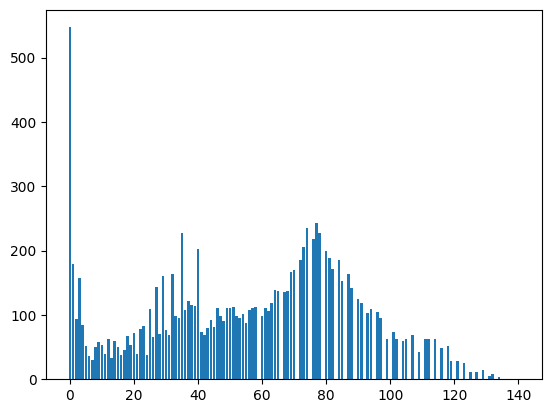

In [54]:
plt.bar(u, c)

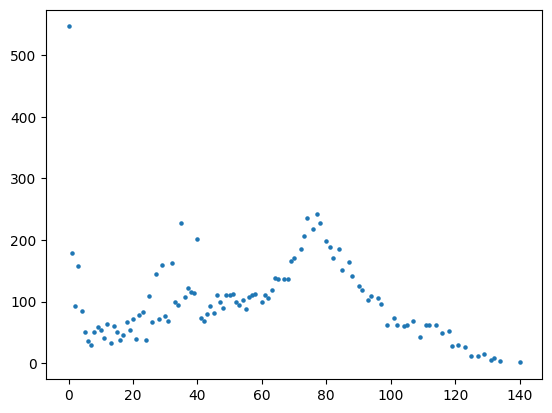

In [ ]:
plt.scatter(u, c, s=5)

In [56]:
# Przejdźmy na prawdopodobieństwo

intensity_probability = c/np.sum(c)
intensity_probability[:10]

array([0.04914645, 0.01608266, 0.0083558 , 0.01419587, 0.00763702,
       0.00458221, 0.0032345 , 0.00269542, 0.00449236, 0.00521114])

(0.0, 255.0)

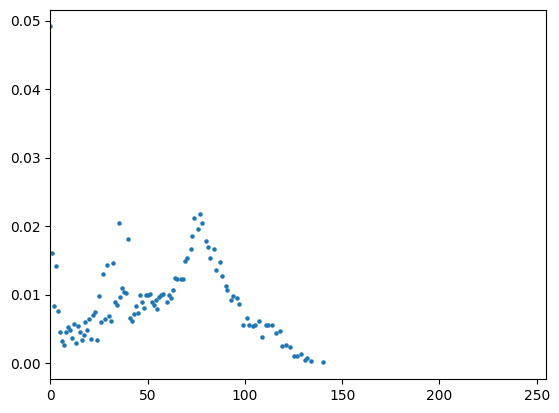

In [57]:
plt.scatter(u, intensity_probability, s=5)
plt.xlim(0,255)